## Stochastic Subspace Descent

In [68]:
from scipy import linalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize._linesearch import scalar_search_armijo
from scipy.optimize import root
from scipy.optimize import rosen, rosen_der
import pycutest
import time

In [69]:
#line profiler
%load_ext line_profiler

The line_profiler extension is already loaded. To reload it, use:
  %reload_ext line_profiler


### Algorithm: 
$$\vec{x}_{k+1} = \vec{x}_k + \alpha \textbf{P}_k \textbf{P}_k^T \nabla f(\vec{x_k})$$
$P \in R^{d \times l}, l \leq d$.  Note $0 < \alpha < 2 \textit{l}/(d\lambda)$

Haar Distributed random matrix: 
$$ \textbf{P} = \sqrt{d \textit{l}} \textbf{Q} \textbf{I}_{d \times l} \in \mathbb{R}^{d \times l}$$

Convergence rate:   
per Corollary 2.3 from 2019 ssd paper, convergence rate under strong convexity should be linear, where 
$$\mathbb{E} f(x_k) - f* \leq \beta^k (f(x_k) - f*), \quad \beta = 1 - l\gamma / d\lambda$$
where $\gamma$ is the smallest eigenvalue of A, and $\lambda$ is the lipschitz constant of the first derivative. 

Note from 5/15/2026 meeting: finding the $\lambda$ may not always be accessible for all functions. So we implement line search in the for-loop for each alpha, and that should yield better results than guessing. 

Think about what could change about the algorithm for nonlinear least squares function of the form
$$ f(\textbf{x}) = \frac{1}{2} \sum_i r_i(\textbf{x})^2 = \frac{1}{2} ||r_i(\textbf{x})||^2$$
where $\nabla f = J^T \textbf{r}$

### Methodology
Need to: 
* define f such that it satisfies all assumptions outline in (D. Kozak et al.)
* define P
* iterative SSD algorithm with input f, P. Output parameters $\textbf{x}^*$ and plot loss function and convergence. 

Then compare results with other methods: 
- with line search: newton, BFGS(quasi-newton)
- without line search: block coordinate descent

### Objective Functions: 
Quadratic: strong convex
$$f(x) = \frac{1}{2} x^T A x - b^T x $$
* lambda is the spectral norm of A, so alpha can be determined
* gamma is the smallest eigenvalue of A (Rayleigh Quotient proof), so beta can be determined
* exact solution can be determined using linalg.solve

Rosenbrock: non-convex
$$f(x) = \sum_{i=1}^{d-1} [100 (x_{i-1} - x_i^2)^2 + (x_i - 1)^2 ]$$
* $\textbf{x}^* = (1, 1, ..., 1), f^* = 0
* need line search for alpha

Sphere Function: convex
$$f(\textbf{x}) = \sum_{i=1}^n x_i^2$$
* global minimum at 0
* $\lambda = 2$ and $\gamma = 2$

Ackley Function: non-convex
$$f(x_1, x_2) = -20 exp[-0.2\sqrt{0.5(x^2 + y^2)}] - exp[0.5(\cos 2 \pi x + \cos 2 \pi y) ] + e + 20$$
* global minimum at 0

## Linesearch For SSD: Wolfe Condition
7/6/2026  
Let $$\phi(t) = f(x_k + t p_k) $$ where $\phi(t): \mathbb{R} \rightarrow \mathbb{R} $  
Let $\Phi(t) \approx \phi(t)$, where $\Phi(t)$ is a quadratic/cubic interpolation of points $\phi(0)$, $\phi(t_1)$, and $\phi'(0)$ (and $\phi(t_2)$ if cubic).   
For SSD, $\phi'(0) = - || p_k||^2 $, so I will modify the scipy code where there's no need to calculate derphi. I will write a function linesearch depending on scipy.optimize.scalar_search_armijo, where then I can fill in the calculation of directional derivative. 

Notes:
* using scipy because it is already the most efficient implementation of linesearch for this method that I know of. Better than writing from scratch.
* using scalar_search_armijo because sufficient decrease condition should be enough, otherwise the curvature condition requires $\phi'$ at each step, largely increase the computational complexity.
* scipy source code reference: https://github.com/scipy/scipy/blob/v1.18.0/scipy/optimize/_linesearch.py#L27
* scalar_search_armijo does sort of backtracking instead of looping through maximum iteration. So it could take a while... need fix?

In [96]:
def estimate_L(hvp, dim, seed=0, iters=30):
    v = np.random.default_rng(seed).standard_normal(dim); v /= np.linalg.norm(v)
    lam = 0.0
    for _ in range(iters):
        w = hvp(v)
        lam = v @ w
        nw = np.linalg.norm(w)
        if nw == 0: break
        v = w / nw
    return abs(lam)

def linesearch(f, xk, pk, derphi0, old_fval=None, alpha0 = 1.0, c1=1e-4, amin=1e-6):
    '''Parameters: 
    f: objective function
    xk: starting point (ndarray)
    pk: search direction (ndarray)
    old_fval: f(xk)
    c1: armijo condition constant
    amin: minimum alpha since there's no curvature condition. 

    return: 
    alpha: new step
    fc: # of function evaluation
    phi1: f value at alpha
    '''
    
    fc = [0]
    def phi(alpha):
        fc[0] += 1
        return f(xk + alpha*pk)

    if old_fval is None: 
        phi0 = phi(0.)
    else:
        phi0 = old_fval

    alpha, phi1 = scalar_search_armijo(
            phi, phi0, derphi0, c1=c1, alpha0=alpha0, amin=amin)

    return alpha, fc[0], phi1

#input alpha and l, independent variables
#0 < alpha < 2l/(d*lambda) 

def ssd(f, gradf, x, l = None, ls=None, max_iter=500, seed=0, amin = 1e-6, L=None, alpha_max = 10):
    '''
    followed algorithm 2.1:
    1: Inputs: α, l. step size, subspace rank
    2: Initialize: x0 . arbitrary initialization
    3: for k = 1, 2, . . . do
    4: Generate P_k
    5: Apply recursion

    updating the linesearch method

    Parameters:
    f: objective functio
    x: starting point x_0
    l: subspace dimension
    alpha = whether or not to implement linesearch

    Return:
    fx: a list of history of function evaluations
    x_history: a list of history of x values
    '''

    #return lists
    fx_history = []
    x_history = []
    stepsize_history = []

    #determining the subspace dimension
    dim = len(x)
    if l is None:
        # default choice for subspace:
        l = min([max([5, int(np.sqrt(dim)) ]), dim])
    if l > dim: raise ValueError('subspace dim should be < dimension')
    if l == dim: print(' Are you sure you want l == dim?')

    
    fval = float(f(x))
    rng = np.random.default_rng(seed)
    alpha0 = float(l)/dim

    if ls == 'off' and L is None:
        raise ValueError("ls='off' requires L")
    if ls == 'off':
        alpha_nols = l / (dim * max(L, 1e-16))
    
    for n in range(max_iter):
        grad = gradf(x)

        if l == dim: #simply gradient descent
            y = grad
            pk = -grad
        else:
            Z = rng.standard_normal((dim, l))
            # Q, _ = linalg.qr(Z, mode='economic', check_finite=False, overwrite_a=True) #economic mode for finding the QR so it's not a full square matrix
            #cholesky reduce the time by a factor of 6
            G = Z.T @ Z                       # l x l
            R = np.linalg.cholesky(G)         # lower triangular
            Q = linalg.solve_triangular(R, Z.T, lower=True).T
            P = np.sqrt(dim / l) * Q 
            y = P.T @ grad
            pk = - P @ y

        if ls == 'on':
            derphi0 = -float(y @ y) #or could be written with pk with a factor l/d. 
            alpha_ls, nfev, phi1 = linesearch(f, x, pk, derphi0, old_fval=fval, alpha0=max(alpha0, amin), amin=amin)
            #if search failed
            if alpha_ls is None:
                alpha_ls, phi1 = 0.0, fval    # null step; fresh subspace next iteration
            else:
                alpha0 = min(2.2 * alpha_ls, alpha_max) #otherwise the armijo algo simply return alpha0
            stepsize_history.append(alpha_ls)
            x = x + alpha_ls * pk
            fval = phi1
        elif ls == 'off':
            x = x + alpha_nols * pk
            fval = float(f(x))
        else:
            raise ValueError ("Please choose linesearch mode.")
        
        #plug x into function
        fx_history.append(fval)
        x_history.append(np.array(x))

    return np.array(fx_history), np.array(x_history), np.array(stepsize_history)

In [81]:
#profiling the ssd algo

print(pycutest.problem_properties('DIXMAANB'))
p = pycutest.import_problem('DIXMAANB')
x = p.x0
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, p.grad, x, ls = 'off', max_iter = int(1e4) )

{'objective': 'other', 'constraints': 'unconstrained', 'regular': True, 'degree': 2, 'origin': 'academic', 'internal': False, 'n': 'variable', 'm': 0}


### Testing using CUTEst Problem Environment
* Documentation for CUTEst: https://jfowkes.github.io/pycutest/_build/html/building.html

In [35]:
#find problem
probs = pycutest.find_problems(constraints='unconstrained', userN=True)
print(probs)

['BOXPOWER', 'SPIN2LS', 'TRIDIA', 'QING', 'NONCVXU2', 'DIXON3DQ', 'MODBEALE', 'NONDIA', 'BROYDN7D', 'QUARTC', 'DIXMAANC', 'ARWHEAD', 'DIXMAANB', 'SBRYBND', 'LUKSAN21LS', 'KSSLS', 'VANDANMSLS', 'BROYDN3DLS', 'SENSORS', '10FOLDTRLS', 'DIXMAANF', 'TQUARTIC', 'YATP2CLS', 'DIXMAANP', 'DIXMAANG', 'POWELLSG', 'SSCOSINE', 'FLETBV3M', 'OSCIGRAD', 'ARGTRIGLS', 'DIXMAAND', 'FMINSURF', 'INDEFM', 'SROSENBR', 'SPINLS', 'VARDIM', 'SPMSRTLS', 'TESTQUAD', 'LUKSAN22LS', 'CHNROSNB', 'SCURLY20', 'GENHUMPS', 'FMINSRF2', 'STRTCHDV', 'SCURLY30', 'DIXMAANM1', 'HILBERTA', 'SINQUAD', 'SPARSINE', 'SCHMVETT', 'CYCLOOCFLS', 'CHAINWOO', 'FLETCHBV', 'FLETCHCR', 'POWER', 'SINQUAD2', 'DIXMAANA1', 'HILBERTB', 'COSINE', 'TOINTGSS', 'CURLY10', 'EDENSCH', 'INTEQNELS', 'YATP1CLS', 'BRYBND', 'EXTROSNB', 'PRICE3', 'CRAGGLVY', 'LUKSAN15LS', 'CURLY20', 'BROWNAL', 'WOODS', 'MSQRTALS', 'CYCLIC3LS', 'ENGVAL1', 'BROYDNBDLS', 'LUKSAN17LS', 'DQRTIC', 'FLETCBV3', 'LIARWHD', 'OSCIPATH', 'BDQRTIC', 'DQDRTIC', 'SCURLY10', 'NONMSQRT', 'F

In [38]:
import os, sys
from contextlib import contextmanager

@contextmanager
def _quiet_fd(fd=2):
    """Silence OS-level fd (2=stderr) around a block — catches compiler/linker stderr
    that bypasses PyCUTEst's quiet=True."""
    stream = sys.stderr if fd == 2 else sys.stdout
    stream.flush()
    saved = os.dup(fd)
    null = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(null, fd); os.close(null)
        yield
    finally:
        stream.flush(); os.dup2(saved, fd); os.close(saved)

def _imp(name, **kw):
    with _quiet_fd(2):
        return pycutest.import_problem(name, quiet=True, **kw)
        
import os, csv, time, io, contextlib, re
import numpy as np

TAUS = (1e-1, 1e-3, 1e-5)

# ---------- evaluation accounting ----------
class BudgetExceeded(Exception): pass

class CountingFn:
    def __init__(self, func, max_evals):
        self.func = func; self.max_evals = max_evals
        self.nfev = 0; self.evals = []; self.vals = []
    def __call__(self, x):
        if self.nfev >= self.max_evals: raise BudgetExceeded
        self.nfev += 1
        v = float(self.func(x))
        self.evals.append(self.nfev); self.vals.append(v)
        return v

def best_so_far(cf):
    evals = np.asarray(cf.evals, dtype=int)
    vals  = np.asarray(cf.vals,  dtype=float)
    fbest = np.empty_like(vals); cur = np.inf
    for i, v in enumerate(vals):
        if np.isfinite(v) and v < cur: cur = v
        fbest[i] = cur
    return evals, fbest

def evals_to_target(evals, fbest, f0, fL, tau):
    target = fL + tau * (f0 - fL)
    hit = np.flatnonzero(fbest <= target)
    return int(evals[hit[0]]) if hit.size else np.inf

def score_ratio(e_off, e_on):
    if np.isinf(e_off) and np.isinf(e_on): return float('nan')
    if np.isinf(e_on):  return float('-inf')
    if np.isinf(e_off): return float('inf')
    return float(np.log10(e_off / e_on))

# ---------- dimension control ----------
def sif_param_options(name):
    """Parse allowed integer SIF parameters from print_available_sif_params (best effort)."""
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            pycutest.print_available_sif_params(name)
    except Exception:
        return {}
    opts = {}
    for m in re.finditer(r'(?m)^\s*([A-Za-z]\w*)\s*=\s*(-?\d+)', buf.getvalue()):
        k, v = m.group(1), int(m.group(2))
        if k.lower() == 'default': continue
        opts.setdefault(k, set()).add(v)
    return {k: sorted(vs) for k, vs in opts.items()}

def choose_import(name, n_min, n_max, overrides):
    """Return (problem, n) sized into [n_min, n_max], else (None, reason)."""
    if name in overrides:
        pr = pycutest.import_problem(name, sifParams=overrides[name], quiet=True)
        return pr, int(pr.n)
    tunable = {k: v for k, v in sif_param_options(name).items() if len(v) > 1}
    if not tunable:                                       # fixed size or capture failed
        pr = pycutest.import_problem(name, quiet=True)
        n = int(pr.n)
        return (pr, n) if n_min <= n <= n_max else (None, f'n={n}_no_param')
    param = max(tunable, key=lambda k: len(tunable[k]))   # dimension parameter
    for v in sorted((v for v in tunable[param] if v <= n_max), reverse=True):
        try:
            pr = pycutest.import_problem(name, sifParams={param: v}, quiet=True)
        except Exception:
            continue
        n = int(pr.n)
        if n > n_max: continue                            # multiplier param (n=3M etc.)
        if n < n_min: break                               # smaller v only shrinks n
        return pr, n
    return None, f'{param}_no_fit'

# ---------- run both variants under a shared eval budget ----------
def run_variants(seed, l, budget_factor, evals_cap):
    n  = int(p.n)
    x0 = np.asarray(p.x0, dtype=float)
    f     = lambda x: float(p.obj(x))
    gradf = lambda x: p.obj(x, gradient=True)[1]
    max_evals = int(min(budget_factor * (n + 1), evals_cap))
    l_eff = l if l is not None else min(max(5, int(np.sqrt(n))), n)
    L = estimate_L(p)                                     # <-- add
    curves = {}
    for tag in ('on', 'off'):
        cf = CountingFn(f, max_evals)
        try:
            ssd(cf, gradf, x0.copy(), l=l, ls=tag, max_iter=max_evals + 5,
                seed=seed, L=(L if tag == 'off' else None))   # <-- add
        except BudgetExceeded:
            pass
        curves[tag] = best_so_far(cf)
    return max_evals, l_eff, curves

# ---------- benchmark loop ----------
def run_benchmark(out_csv='ssd_ls_vs_fixed.csv', n_min=10, n_max=120,
                  budget_factor=1000, evals_cap=8000, seed=0, l=None,
                  degenerate_rtol=1e-8, overrides=None, limit=None):
    global p
    overrides = overrides or {}
    probs = sorted(pycutest.find_problems(constraints='unconstrained', userN=True))
    if limit: probs = probs[:limit]
    fields = (['problem','n','l','max_evals','seed','f0','fL','degenerate','status','seconds']
              + [f'{k}_tau{t:g}' for t in TAUS for k in ('evals_on','evals_off','score')])
    new = not os.path.exists(out_csv)
    with open(out_csv, 'a', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=fields)
        if new: w.writeheader(); fh.flush()
        for name in probs:
            row = {k: '' for k in fields}; row['problem'] = name; row['seed'] = seed
            t0 = time.time()
            try:
                pr, info = choose_import(name, n_min, n_max, overrides)
                if pr is None:
                    row['status'] = f'skip_{info}'
                else:
                    p = pr                                # activate for ssd
                    row['n'] = int(p.n)
                    max_evals, l_eff, curves = run_variants(seed, l, budget_factor, evals_cap)
                    row['l'] = l_eff; row['max_evals'] = max_evals
                    (ev_on, fb_on), (ev_off, fb_off) = curves['on'], curves['off']
                    f0 = fb_on[0]
                    if not np.isfinite(f0):
                        row['status'] = 'bad_f0'
                    else:
                        fL = float(min(fb_on[-1], fb_off[-1]))
                        row['f0'] = f0; row['fL'] = fL
                        degen = (f0 - fL) <= degenerate_rtol * max(1.0, abs(f0))
                        row['degenerate'] = int(degen)
                        for t in TAUS:
                            if degen:
                                e_on = e_off = s = float('nan')
                            else:
                                e_on  = evals_to_target(ev_on,  fb_on,  f0, fL, t)
                                e_off = evals_to_target(ev_off, fb_off, f0, fL, t)
                                s = score_ratio(e_off, e_on)
                            row[f'evals_on_tau{t:g}']  = e_on
                            row[f'evals_off_tau{t:g}'] = e_off
                            row[f'score_tau{t:g}']     = s
                        row['status'] = 'ok'
            except Exception as e:
                row['status'] = f'error:{type(e).__name__}'
            row['seconds'] = round(time.time() - t0, 2)
            w.writerow(row); fh.flush()
            print(f"{name:12s} {row['status']:>16s}  n={row['n']}  {row['seconds']}s")
    return out_csv

def summarize(out_csv):
    import pandas as pd
    df = pd.read_csv(out_csv); ok = df[df['status'] == 'ok']; use = ok[ok['degenerate'] == 0]
    print(f"ok:{len(ok)}  degenerate:{int(ok['degenerate'].sum())}  scored:{len(use)}")
    for t in TAUS:
        s = use[f'score_tau{t:g}'].astype(float); fin = s[np.isfinite(s)]
        print(f"tau={t:g}: ls-on wins {int((s>0).sum())}, fixed wins {int((s<0).sum())}, "
              f"tie {int((s==0).sum())}; median finite {fin.median():+.3f} (n={len(fin)})")

In [39]:
print(repr(sif_param_options('ARWHEAD')))   # expect {'N': [...]}. If {} => see note below.
run_benchmark()                               # full
summarize('ssd_ls_vs_fixed.csv')

{'N': [100, 500, 1000, 5000]}
10FOLDTRLS   skip_n=1000_no_param  n=  0.01s
ARGLINA                    ok  n=10  0.29s
ARGLINB                    ok  n=100  1.37s
ARGLINC                    ok  n=100  1.34s
ARGTRIGLS                  ok  n=100  0.84s
ARWHEAD                    ok  n=100  0.23s
BDQRTIC                    ok  n=100  0.31s
BOX                        ok  n=100  0.32s
BOXPOWER                   ok  n=100  0.3s
BROWNAL                    ok  n=100  0.59s
BROYDN3DLS                 ok  n=100  0.24s
BROYDN7D     skip_n=5000_no_param  n=  0.01s
BROYDNBDLS                 ok  n=100  0.34s
BRYBND                     ok  n=100  0.34s
CHAINWOO                   ok  n=100  0.31s
CHNROSNB                   ok  n=50  0.19s
CHNRSNBM                   ok  n=50  0.2s
COSINE                     ok  n=100  0.33s
CRAGGLVY                   ok  n=100  0.32s
CURLY10                    ok  n=100  0.3s
10FOLDTRLS   skip_n=1000_no_param  n=  0.01s
ARGLINA                    ok  n=10  0.26s
ARGLIN

/var/folders/2m/ffpxvj6x6y9_869rd2330sl00000gn/T/ipykernel_51695/533425615.py:101: RuntimeWarning: invalid value encountered in matmul
  y = P.T @ grad


TQUARTIC                   ok  n=100  0.31s
TRIDIA                     ok  n=100  0.29s
TRIGON1                    ok  n=100  0.81s
TRIGON2                    ok  n=100  0.41s
VANDANMSLS                 ok  n=22  0.18s
VARDIM                     ok  n=100  0.28s
VAREIGVL                   ok  n=100  0.36s
WATSON                     ok  n=31  0.21s
WOODS                      ok  n=100  0.3s
YATP1CLS                   ok  n=120  0.56s
YATP1LS                    ok  n=120  0.56s
YATP2CLS                   ok  n=120  0.54s
YATP2LS                    ok  n=120  0.53s
ok:144  degenerate:0  scored:144
tau=0.1: ls-on wins 102, fixed wins 39, tie 3; median finite +0.260 (n=119)
tau=0.001: ls-on wins 108, fixed wins 36, tie 0; median finite +0.713 (n=87)
tau=1e-05: ls-on wins 103, fixed wins 41, tie 0; median finite +0.413 (n=42)


In [41]:
df = pd.read_csv('ssd_ls_vs_fixed.csv').drop_duplicates(subset='problem', keep='last')
use = df[(df['status'] == 'ok') & (df['degenerate'] == 0)].copy()

tau = '1e-05'
e_on  = pd.to_numeric(use[f'evals_on_tau{tau}'],  errors='coerce')
e_off = pd.to_numeric(use[f'evals_off_tau{tau}'], errors='coerce')

wins = use[e_on < e_off]           # ls-on reached the target in fewer evals
print(wins[['problem', 'n', f'evals_on_tau{tau}', f'evals_off_tau{tau}']]
      .sort_values('n').to_string(index=False))

   problem     n  evals_on_tau1e-05  evals_off_tau1e-05
CYCLOOCFLS  20.0              371.0                 inf
VANDANMSLS  22.0             7994.0                 inf
  EIGENCLS  30.0             1678.0              4351.0
    WATSON  31.0             7754.0                 inf
   EDENSCH  36.0              117.0              2982.0
  ERRINROS  50.0              219.0                 inf
  CHNRSNBM  50.0             7966.0                 inf
  CHNROSNB  50.0             7970.0                 inf
  ERRINRSM  50.0              296.0                 inf
  FMINSURF  64.0             1237.0              4498.0
  FMINSRF2  64.0             7964.0                 inf
    SPINLS  67.0             7866.0                 inf
  DIXMAANG  90.0              324.0                 inf
  DIXMAANN  90.0             1087.0                 inf
  DIXMAANL  90.0              223.0                 inf
  DIXMAANJ  90.0              723.0                 inf
  DIXMAANO  90.0              729.0             

### visualization

{'objective': 'other', 'constraints': 'unconstrained', 'regular': True, 'degree': 2, 'origin': 'academic', 'internal': False, 'n': 'variable', 'm': 0}
size of x: 3000
with linesearch
47080.66596820195 → 3.5065291620902843
{'f': 997, 'g': 500, 'H': 0, 'Hprod': 0, 'tsetup': 0.0, 'trun': 2718.0, 'c': None, 'cg': None, 'cH': None}
without linesearch
46623.47088983235 → 3715.1239010226755
{'f': 1498, 'g': 1000, 'H': 30, 'Hprod': 30, 'tsetup': 0.0, 'trun': 2727.0, 'c': None, 'cg': None, 'cH': None}


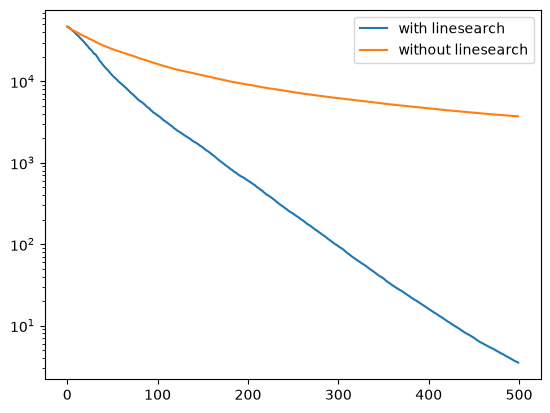

In [105]:
print(pycutest.problem_properties('DIXMAANB'))
p = pycutest.import_problem('DIXMAANB')
x = p.x0

fx_ls, xs_ls, ls_hist = ssd(p.obj, p.grad, x, ls = 'on')
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, p.grad, x, max_iter = int(1e4) )
print(f'size of x: {x.size}')
print("with linesearch")
print(fx_ls[0], '→', fx_ls[-1])
print(p.report())

#without linesearch
L = estimate_L(lambda v: p.hprod(v, x=x), x.size)
fx, xs, _ = ssd(p.obj, p.grad, x, ls = 'off', L = L)
print("without linesearch")
print(fx[0], '→', fx[-1])
print(p.report())

fig, ax = plt.subplots()
ax.semilogy(fx_ls, label = 'with linesearch')
ax.semilogy(fx, label = 'without linesearch')
ax.legend()
plt.show()

#### Outline the function for objective functions: 

considerations: 
- objective function defined as f, the lambda function.
- if a function has a known lambda, use it. Otherwise do line search on alpha. 
- if a function has a known solution, use it. Otherwise solve using scipy.linalg.solve
- find gamma.
- plot the convergence against strong convex, convex, and non-convex lines.
- build a class? yes

```
def eval(objective function, known lambda=false, f_exact=false, x, l, max_iter=)
    find alpha, lambda, beta, f_exact
    evaluate using ssd()
    plot
    return None
```

f (exact) = 0
final f = 0.3621689975261688
x history = [0.947667   0.9785799  0.33229148 0.46866846] [0.85710067 0.7555211  0.56372106 0.33850145]


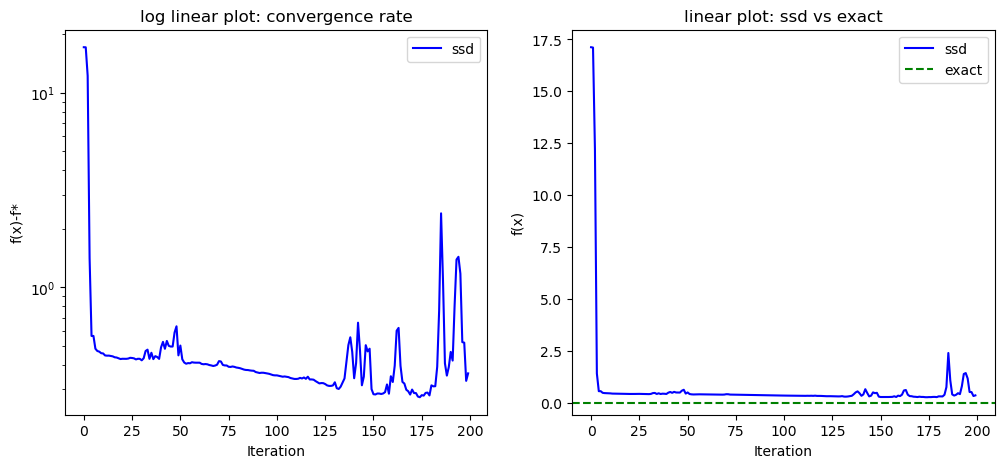

In [5]:
'''these code are from first time writing SSD algorithm and testing it. Learning phase'''
# conv = "strong convex" or "convex" or "nonconvex"
# sol_np needs to be a numpy array
def eval(ObjFnc, x, l, lam=None, sol_np=None, conv='', gamma=None):

    dim = x.shape[0]
    if sol_np is not None:
        f_exact = sol_np
    else:
        #solve a general function. Only solve quadratic rn
        x_exact = linalg.solve(A,b, assume_a = 'pos')
        f_exact = f(x_exact)

    if lam:
        alpha = l /(dim*lam)
        result, x_history = ssd(x, l, ObjFnc, dim, alpha)
    else:
        result, x_history = ssd(x, l, ObjFnc, dim)
        
    print("f (exact) =", f_exact)
    print("final f =", result[-1])
    print("x history =", x_history[0], x_history[-1])
    
    #plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.set_title('log linear plot: convergence rate')
    ax1.semilogy(result - f_exact, color='b', label='ssd')
    
    if conv == "strong convex" or conv == "convex":
        initial_gap = result[0] - f_exact
        k = np.arange(1, len(result) + 1)
        if conv == "strong convex":
            beta = 1 - (l * gamma)/ (dim*lam)
            ax1.semilogy(beta**k * initial_gap, color='r', ls='dashed', label='strong-conv conv. rate (linear)')
        else:
            sublinear_rate = sublinear_rate = initial_gap / k
            ax1.semilogy(sublinear_rate, color='g', ls='dashed', label='convex conv. rate (sublinear)')
            
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("f(x)-f*")
    ax1.legend()
    
    ax2.set_title('linear plot: ssd vs exact')
    ax2.plot(result, color='b', label='ssd')
    ax2.axhline(f_exact, color='g', label='exact', ls='dashed')
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("f(x)")
    ax2.legend()
    
    plt.show()

    return None

'''testing for the original ssd function without CUTEst and improved linesearch. '''
key = jax.random.PRNGKey(0)
x = jax.random.uniform(key, shape=(4))

# # evaluate quadratic
# key = jax.random.PRNGKey(0)
# A = np.random.randn(4,4)
# A = A@A.T + 0.1 * np.eye(4)#A needs to be positive definite
# print(A)
# b = np.array([2, 4, 1, 3])
# quad = lambda x: (0.5) * x.T @ A @ x - b.T @ x
# eval(quad, x, 2, lam = linalg.norm(A, ord=2), conv = "strong convex")

#non-convex function: Rosenbrock. Need to look into non-convex function convergence. 
rosen = lambda x: sum(100*(x[i+1] - x[i]**2)**2 + (1 - x[i])**2 
                  for i in range(len(x)-1))
eval(rosen, x, 2, sol_np=np.array(0))

# # convex function: sphere
# sphere = lambda x: sum(x[i]**2 for i in range(len(x)-1))
# #find lambda and gamma by hand
# eval(sphere, x, 2, lam=2, gamma=2, sol_np=np.array(0), conv="convex")

# #ackley function: non-convex
# x = jnp.array([0.3, 0.3])  
# ackley = lambda x: -20 * jnp.exp(-0.2 * jnp.sqrt(np.mean(x**2))) - jnp.exp(np.mean(jnp.cos(2 * np.pi * x))) + 20 + jnp.e
# eval(ackley, x, 2, sol_np=np.array(0), conv="nonconvex")
# #ackley function seems to be stuck in the local min and doesn't converge to global min, is that to be expected or not? 

In [7]:
# #newton's method w/o line search: alpha = 1
# def newton(x0, f, max_iter=100, tol=1e-6):
#     fx = []
#     x = jnp.array(x0, dtype=float)
#     for n in range(max_iter):
#         grad = jax.grad(f)(x)

#         #test tolerance
#         if linalg.norm(grad) < tol:
#             print (f" f (without line search) converged at iteration {n}")
#             break

#         H = jax.hessian(f)(x)
#         p = linalg.solve(H, -grad)
#         x = x + p
#         fx.append(f(x))
#     return fx

In [174]:
# #newton's method with line search: 
# def newton_ls(x0, f, max_iter=100, tol=1e-6):
#     fx = []
#     x = jnp.array(x0, dtype=float)
#     grad_fn = lambda x: np.array(jax.grad(f)(jnp.array(x)))
#     f_np = lambda x: float(f(jnp.array(x)))
    
#     for n in range(max_iter):
#         grad = jax.grad(f)(x)

#         #test tolerance
#         if linalg.norm(grad) < tol:
#             print (f" f (with line search) converged at iteration {n}")
#             break

#         H = jax.hessian(f)(x)
#         p = linalg.solve(H, -grad)

#         #wolfe condition line search
#         #scipy.optimize.line_search uses numpy array and functions. 
#         alpha = line_search(f_np, grad_fn, np.array(x), np.array(p))
        
#         x = x + alpha[0] * p
#         fx.append(f(x))
#     return fx

# result_nls = newton_ls(np.random.rand(4).tolist(), f)

 f (with line search) converged at iteration 1


## Modified G-N Stochastic Subspace Descent for Nonlinear Least Squares
Oracle: ${r_i(x)}^m_{i=1} = {q^\top \nabla r_i(x)}^m_{i=1} = J(x)q$ where q is a directional derivative. 

We know $r(x_k + p) = r(x_k) + J(x_k)p$ is the residual function. The nonlinear least square problem is then $$ \min_x ||r(x_k) + J(x_k)p||^2_2 $$

Apply $p = Pn$ to the SSD algorithm, where P is a projection matrix of size $d \times l$ where $l < d$. After applying the substitution, we obtain the normal equation 
\begin{equation}
-(JP)^\top r = (JP)^\top (JP) n
\end{equation}
solving for $n^*$ we have 
$$ Pn = p = P(P^\top J^\top J P)^{-1} P^\top J^\top r $$
Let $P = Q \cdot S$, where the column space of P and Q is the same and $S^{-1}$ exists. Then 
$$ p = Q(Q^\top J^\top J Q)^{-1} Q^\top J^\top r $$
Let $\tilde{J} = J \cdot Q$, then 
$$ p = Q ( \tilde{J}^\top \tilde{J} ) ^{-1} \tilde{J}^\top r$$
and the algorithm costs $l$ for $l$ directional derivatives. 

For computing purposes, compute by finding
$$ p = \text{arg} \min_{n \in \mathbb{R}} ||\tilde{J}n - r_x||^2_2$$

### Linesearch Algo
Similar to the original SSD version except $\phi'(0) = J p_k$, which is also already computed in current step. No extra step needed. Using armijo condition. 

In [113]:
def gn_ssd(x, cons, l=None, ls=None, max_iter=200, seed=0, amin=1e-10):
    '''
    input: x is the starting point; P is dxl; r the residual function
    Q has Haar distribution
    Assume alpha = 1
    iteration: x = P
    '''

    dim = len(x)
    rng = np.random.default_rng(seed)

    #return variables
    x_history = []
    fx_history = []
    stepsize_history = []

    #subspace dimension
    dim = len(x)
    if l is None:
        # default choice for subspace:
        l = min([max([5, int(np.sqrt(dim)) ]), dim])
    if l > dim: raise ValueError('subspace dim should be < dimension')
    if l == dim: print(' Are you sure you want l == dim?')

    #define f as a function than a value
    def fobj(z): rz = cons(z); return 0.5*np.dot(rz, rz)
    alpha0 = 1.0
    
    for n in range(max_iter):
        r , J = cons(x, gradient=True) #residual and Jacobian
        fval = 0.5 * np.dot(r, r)
        
        Z = rng.standard_normal((dim, l))
        Q, _ = linalg.qr(Z, mode='economic') #economic mode for finding the QR so it's not a full square matrix

        #solving for the step
        J_tild = J @ Q
        pk = np.linalg.lstsq(J_tild, - r, rcond=None)[0]

        if ls == 'on':
            derphi0 = (J_tild.T @ r) @ pk
            direc = Q @ pk
            alpha_ls, nfev, phi1 = linesearch(fobj, x, direc, derphi0, old_fval=fval,alpha0=max(alpha0, amin), amin=amin)
            #if it fails
            if alpha_ls is None: 
                alpha_ls, phi1 = 0.0, fval
            else:
                alpha0 = 2.5 * alpha_ls
            stepsize_history.append(alpha_ls)
            fval = phi1
            x = x + alpha_ls * direc
        elif ls == 'off': #alpha = 1
            x = x + Q @ pk
            fval = float(fval)
        else:
            raise ValueError("please choose linesearch mode.")

        x_history.append(np.array(x))
        fx_history.append(fval)

    return np.array(fx_history), np.array(x_history), np.array(stepsize_history)

In [114]:
nls_prob = pycutest.find_problems(objective='none', constraints='linear quadratic other', regular=True)
nls_prob[:10]

['HATFLDFLNE',
 'ENGVAL2NE',
 'SSBRYBNDNE',
 'BOXBOD',
 'PALMER1BNE',
 'SINVALNE',
 'BIGGS6NE',
 'CERI651A',
 'CHANDHEQ',
 'MGH09']

{'objective': 'none', 'constraints': 'other', 'regular': True, 'degree': 2, 'origin': 'real-world', 'internal': False, 'n': 'variable', 'm': 'variable'}
size of x_i: 100
with linesearch
3.216290580280907 → 0.02823911036356455
without linesearch
3.461682721621411 → 0.028494405739662138
{'f': 0, 'g': 0, 'H': 0, 'Hprod': 0, 'c': 799, 'cg': 400, 'cH': 0, 'tsetup': 0.0, 'trun': 0.0}


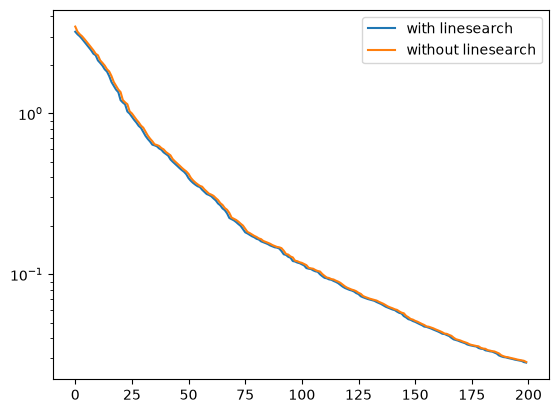

In [115]:
#test the gn_ssd algorithm
print(pycutest.problem_properties('CHANDHEQ'))
p = pycutest.import_problem('CHANDHEQ')
x = p.x0

fx_ls, xs_ls, ls_hist = gn_ssd(x, p.cons, ls = 'on')
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, p.grad, x, max_iter = int(1e4) )
print(f'size of x_i: {x.size}')
print("with linesearch")
print(fx_ls[0], '→', fx_ls[-1])

#without linesearch
fx, xs, _ = gn_ssd(x, p.cons, ls = 'off')
print("without linesearch")
print(fx[0], '→', fx[-1])
print(p.report())

fig, ax = plt.subplots()
ax.semilogy(fx_ls, label = 'with linesearch')
ax.semilogy(fx, label = 'without linesearch')
ax.legend()
plt.show()

### Algorithm to compare GN-SSD to
* IBCDFO: https://github.com/POptUS/IBCDFO.git
* Cartis' A Randomised Subspace Gauss-Newton Method for Nonlinear Least-Squares (no code tho... would be great comparison)
* DFBGN: https://github.com/numericalalgorithmsgroup/dfbgn (also from the other Cartis paper)

In [122]:
import ibcdfo

p = pycutest.import_problem('ARGLALE', sifParams={'N': 50, 'M': 100})
n, m = p.n, p.m
X0 = np.asarray(p.x0, dtype=float)
Ffun = p.cons                     # bound method: pinned to THIS p, no late lookup
nf_max = 100 * (n + 1)
Low, Upp = -np.inf*np.ones(n), np.inf*np.ones(n)

# X, F, hF, flag, xk_best = pounders(Ffun, X0, n, nf_max, 1e-13, 0.1, m, Low, Upp)
ibcdfo.run_pounders(Ffun, X0, n, nf_max, 1e-10, 0.1, m, Low, Upp)
print(flag, hF.shape)
print(hF[0], np.dot(Ffun(X0), Ffun(X0)))
f_curve_p = np.minimum.accumulate(hF / 2.0)
print(f_curve_p[0], f_curve_p[-1])

Terminating because delta_min reached with a valid model.
-6 (983,)
250.00000000000023 250.00000000000023
125.00000000000011 24.999999999999943
